<a href="https://colab.research.google.com/github/RAGNON666/FINAL/blob/main/Grafos_Octubre_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DIAGNÓSTICO DE SISTEMA
Versión de Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
[OK] NetworkX versión: 3.7
[OK] Matplotlib versión: 3.10.0
[OK] Backend Gráfico: module://matplotlib_inline.backend_inline

Probando generación de ventana gráfica...
Si ves una ventana con dos nodos, tu IDLE está 100% listo.


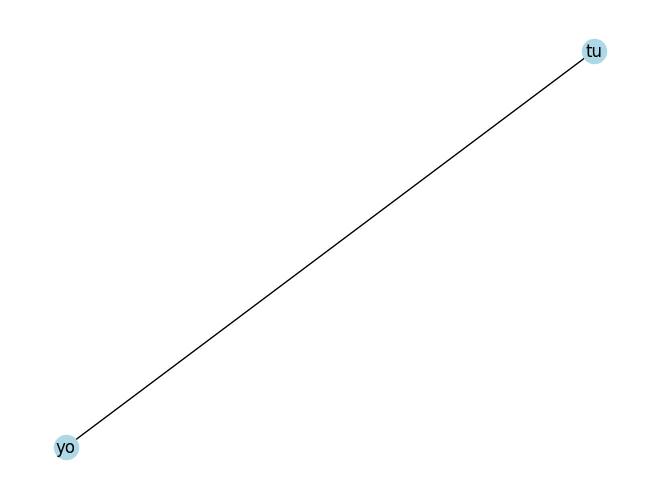

"\nNOTAS PARA EL ALUMNO:\n1. Si el programa falla al inicio, es porque las bibliotecas no están instaladas.\n2. Si el programa imprime las versiones pero NO abre la ventana, hay un problema\n   con el Backend de Tkinter (común en algunas instalaciones de Linux o Mac).\n3. 'plt.show()' es una función bloqueante: el programa no terminará hasta que\n   cierres la ventana del gráfico.\n\n\nverificar que pip este instalado\npython -m ensurepip --upgrade\n\n"

In [3]:
# 1.- ---------------- Encabezado ----------------------------------------------
# Autor : Jorge Anzaldo
# Fecha : Noviembre de 2026
# Descripcion del programa :
# Test de Diagnóstico de Ambiente. Verifica la instalación de NetworkX y
# Matplotlib, y valida que el motor gráfico (Backend) funcione correctamente.

# 2.- ---------------- Importación de Módulos y Bibliotecas --------------------
import sys

try:
    import networkx as nx
    import matplotlib.pyplot as plt
    import matplotlib
    LIBRERIAS_LISTAS = True
except ImportError as e:
    LIBRERIAS_LISTAS = False
    ERROR_MSG = str(e)

# 3.- ---------------- Definición de Funciones o clases ------------------------
def realizar_diagnostico():
    """Imprime información técnica sobre el entorno actual."""
    print(f"{'='*40}")
    print(f"DIAGNÓSTICO DE SISTEMA")
    print(f"{'='*30}")
    print(f"Versión de Python: {sys.version}")

    if LIBRERIAS_LISTAS:
        print(f"[OK] NetworkX versión: {nx.__version__}")
        print(f"[OK] Matplotlib versión: {matplotlib.__version__}")
        print(f"[OK] Backend Gráfico: {matplotlib.get_backend()}")
    else:
        print(f"[ERROR] Falta una biblioteca: {ERROR_MSG}")
        print("\nInstrucción de reparación:")
        print("Ejecuta en tu terminal: pip install networkx matplotlib")



# 5.- ---------------- Bloque Principal ----------------------------------------
if __name__ == "__main__":
    realizar_diagnostico()

    if LIBRERIAS_LISTAS:
        print("\nProbando generación de ventana gráfica...")
        # Crear un grafo vacío mínimo para probar el renderizado
        prueba_g = nx.Graph()
        prueba_g.add_edge("yo", "tu")

        nx.draw(prueba_g, with_labels=True, node_color='lightblue')

        print("Si ves una ventana con dos nodos, tu IDLE está 100% listo.")
        plt.show()
    else:
        print("\nEl ambiente no está configurado. Revisa los errores arriba.")


Iniciando motor de renderizado...
Cerrar la ventana del gráfico para finalizar el programa.


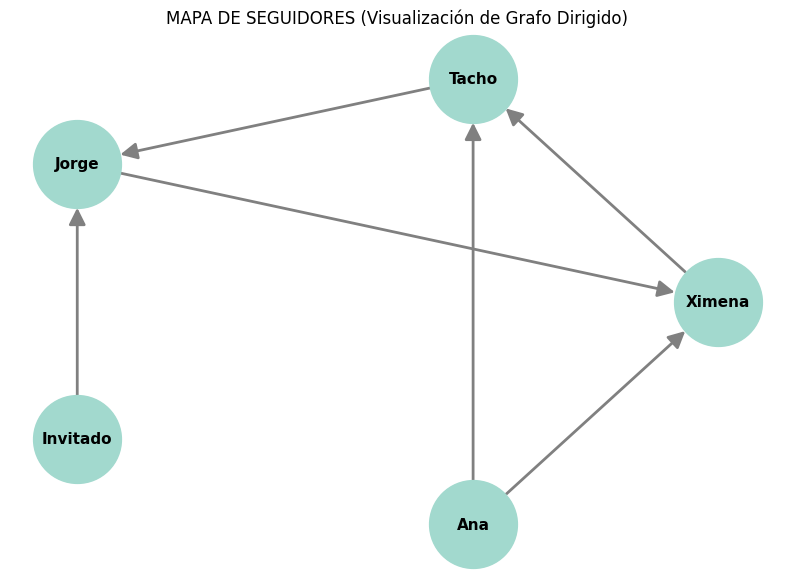

In [ ]:
# 1.- ---------------- Encabezado ----------------------------------------------
# Autor : Jorge Anzaldo
# Fecha : Noviembre de 2026
# Descripcion del programa :
# Introducción a la visualización de Grafos Dirigidos utilizando la librería
# NetworkX y Matplotlib. El programa vincula una estructura de datos manual
# (Lista Simplemente Enlazada) con un objeto gráfico para representar redes sociales.

# 2.- ---------------- Importación de Módulos y Bibliotecas --------------------
import networkx as nx      # Biblioteca especializada en el estudio de Grafos y Redes.
import matplotlib.pyplot as plt # Biblioteca para la generación de gráficos y visualización.

# 3.- ---------------- Definición de Funciones o clases ------------------------

class Nodo:
    """Estructura básica de un nodo para la lista enlazada."""
    def __init__(self, dato):
        self.dato = dato
        self.siguiente = None

class ListaConexiones:
    """
    Gestión manual de adyacencias. Esta clase representa el 'quién sigue a quién'
    usando punteros, tal como se ve en teoría de estructuras de datos.
    """
    def __init__(self):
        self.inicio = None

    def insertar(self, destino):
        """Inserta un nuevo destino al inicio de la lista (Complejidad O(1))."""
        nuevo = Nodo(destino)
        nuevo.siguiente = self.inicio
        self.inicio = nuevo

class RedSocialVisual:
    """
    Clase puente que conecta la lógica de Listas Enlazadas con
    la potencia visual de NetworkX.
    """
    def __init__(self):
        # Estructura manual: Diccionario de Listas Enlazadas
        self.adyacencias = {}
        # Estructura de NetworkX: Objeto de Grafo Dirigido (DiGraph)
        self.g = nx.DiGraph()

    def agregar_usuario(self, nombre):
        """Crea un vértice en ambas estructuras."""
        if nombre not in self.adyacencias:
            self.adyacencias[nombre] = ListaConexiones()
            self.g.add_node(nombre)

    def seguir_a(self, seguidor, seguido):
        """
        Crea una arista o conexión dirigida.
        En grafos dirigidos, el orden importa: A -> B no es lo mismo que B -> A.
        """
        # 1. Registro en nuestra estructura de listas manual
        self.adyacencias[seguidor].insertar(seguido)
        # 2. Registro en NetworkX para permitir el dibujo
        self.g.add_edge(seguidor, seguido)

    def graficar(self):
        """Configura y despliega la ventana con el gráfico."""
        plt.figure(figsize=(10, 7))
        plt.title("MAPA DE SEGUIDORES (Visualización de Grafo Dirigido)")

        # 'pos' define la ubicación de los nodos. circular_layout los pone en círculo
        # para que las flechas y ciclos sean fáciles de identificar.
        pos = nx.circular_layout(self.g)

        # Dibujamos el grafo con estilos personalizados
        nx.draw(self.g, pos,
                with_labels=True,        # Muestra los nombres de los nodos
                node_color='#A2D9CE',    # Color verde pastel
                node_size=4000,          # Tamaño del círculo
                font_size=11,
                font_weight='bold',
                arrowsize=25,            # Tamaño de la punta de la flecha
                edge_color='gray',       # Color de la línea de conexión
                width=2)                 # Grosor de la línea

        plt.show() # Dispara la ventana gráfica

# 4.- ---------------- Variables u Objetos Globales ----------------------------
# No se requieren para este ejemplo educativo.

# 5.- ---------------- Bloque Principal ----------------------------------------
if __name__ == "__main__":
    # Instanciamos nuestra red social
    red = RedSocialVisual()

    # Paso 1: Definir los integrantes de la red (Vértices)
    usuarios = ["Ximena", "Tacho", "Jorge", "Invitado", "Ana"]
    for u in usuarios:
        red.agregar_usuario(u)

    # Paso 2: Crear los vínculos (Aristas Dirigidas)
    # Leemos esto como: "A sigue a B"
    red.seguir_a("Ximena", "Tacho")
    red.seguir_a("Tacho", "Jorge")
    red.seguir_a("Invitado", "Jorge")
    red.seguir_a("Jorge", "Ximena")  # Esto crea un ciclo: Ximena -> Tacho -> Jorge -> Ximena
    red.seguir_a("Ana", "Tacho")
    red.seguir_a("Ana", "Ximena")

    # Paso 3: Mostrar resultado
    print("Iniciando motor de renderizado...")
    print("Cerrar la ventana del gráfico para finalizar el programa.")
    red.graficar()

# 6.- ---------------- Documentación y Comentarios------------------------------

#CONCEPTOS CLAVE:

#1. ¿Qué es un Grafo Dirigido (DiGraph)?:
#   Es aquel donde las conexiones tienen un sentido único. Se representa con flechas.

#2. NetworkX vs Estructura Manual:
#   - La estructura manual (ListaConexiones) nos sirve para entender cómo se guardan
#     los datos en memoria (punteros).
#   - NetworkX nos ahorra el trabajo matemático de calcular coordenadas (X, Y) para
#     dibujar los nodos en pantalla.

#3. Librerías utilizadas:
#   - NetworkX: Procesa la "topología" (quién está conectado con quién).
#   - Matplotlib: Es el "lienzo" donde se dibuja el resultado de NetworkX.

#4. Importancia de 'pos' (Layout):
#   Existen diferentes formas de acomodar nodos:
#   - nx.spring_layout: Los nodos se repelen como imanes.
#   - nx.circular_layout: Los acomoda en un círculo perfecto.
#   - nx.random_layout: Los coloca al azar.


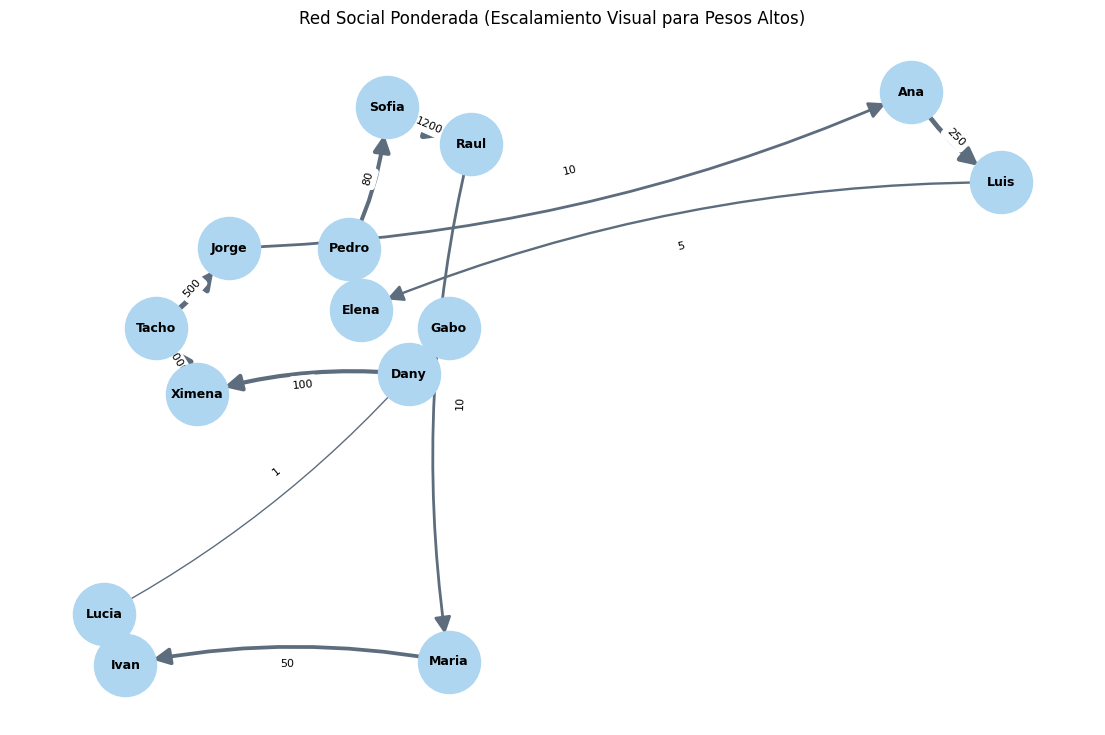


MATRIZ DE ADYACENCIA (Pesos Reales)


,Ximena,Tacho,Jorge,Ana,Luis,Elena,Pedro,Sofia,Raul,Maria,Ivan,Lucia,Gabo,Dany
Ximena,0,1000,0,0,0,0,0,0,0,0,0,0,0,0
Tacho,0,0,500,0,0,0,0,0,0,0,0,0,0,0
Jorge,0,0,0,10,0,0,0,0,0,0,0,0,0,0
Ana,0,0,0,0,250,0,0,0,0,0,0,0,0,0
Luis,0,0,0,0,0,5,0,0,0,0,0,0,0,0
Elena,0,0,0,0,0,0,1500,0,0,0,0,0,0,0
Pedro,0,0,0,0,0,0,0,80,0,0,0,0,0,0
Sofia,0,0,0,0,0,0,0,0,1200,0,0,0,0,0
Raul,0,0,0,0,0,0,0,0,0,10,0,0,0,0
Maria,0,0,0,0,0,0,0,0,0,0,50,0,0,0


In [ ]:
# 1.- ---------------- Encabezado ----------------------------------------------
# Autor : Jorge Anzaldo
# Fecha : Noviembre de 2026
# Descripcion del programa :
# Grafo Dirigido Ponderado con Escalamiento Visual de Aristas.
# Evita la distorsión por pesos elevados y gestiona 14 nodos en Google Colab.

# 2.- ---------------- Importación de Módulos y Bibliotecas --------------------
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np # Para normalización matemática

# 3.- ---------------- Definición de Funciones o clases ------------------------

class Nodo:
    def __init__(self, dato):
        self.dato = dato
        self.siguiente = None

class ListaSimplementeEnlazada:
    def __init__(self):
        self.inicio = None

    def insertar(self, objeto_nuevo):
        nuevo_nodo = Nodo(objeto_nuevo)
        nuevo_nodo.siguiente = self.inicio
        self.inicio = nuevo_nodo

    def contiene(self, identificador_buscar):
        actual = self.inicio
        while actual:
            primer_atributo = list(vars(actual.dato).values())[0]
            if primer_atributo == identificador_buscar:
                return True
            actual = actual.siguiente
        return False

    def obtener_identificadores(self):
        actual = self.inicio
        elementos = []
        while actual:
            primer_atributo = list(vars(actual.dato).values())[0]
            elementos.append(str(primer_atributo))
            actual = actual.siguiente
        return " -> ".join(elementos) if elementos else "Sin conexiones"

class Grafo:
    def __init__(self):
        self.almacen_objetos = []
        self.lista_identificadores = []
        self.listas_adyacencia = {}
        self.matriz = []
        self.g_visual = nx.DiGraph()

    def agregar_vertice(self, objeto_nuevo):
        identificador = list(vars(objeto_nuevo).values())[0]
        if identificador not in self.lista_identificadores:
            self.almacen_objetos.append(objeto_nuevo)
            self.lista_identificadores.append(identificador)
            self.listas_adyacencia[identificador] = ListaSimplementeEnlazada()
            self.g_visual.add_node(identificador)
            for fila in self.matriz:
                fila.append(0)
            self.matriz.append([0] * len(self.lista_identificadores))

    def _buscar_posicion(self, identificador):
        try: return self.lista_identificadores.index(identificador)
        except ValueError: return None

    def agregar_arista(self, origen, destino, es_dirigido=True, peso=1):
        pos_o = self._buscar_posicion(origen)
        pos_d = self._buscar_posicion(destino)
        if pos_o is not None and pos_d is not None:
            if not self.listas_adyacencia[origen].contiene(destino):
                self.listas_adyacencia[origen].insertar(self.almacen_objetos[pos_d])
                self.matriz[pos_o][pos_d] = peso
                self.g_visual.add_edge(origen, destino, weight=peso)

    def mostrar_grafo(self):
        plt.figure(figsize=(14, 9))
        # k controla la distancia entre nodos para evitar amontonamiento
        pos = nx.spring_layout(self.g_visual, k=1.8, seed=42)

        # --- SOLUCIÓN A LA DISTORSIÓN ---
        # Extraemos pesos y aplicamos escala logarítmica para el ancho visual (width)
        raw_weights = [self.g_visual[u][v]['weight'] for u, v in self.g_visual.edges()]
        # El grosor visual será: 1 + log10(peso). Si peso=1000, ancho=4. Si peso=1, ancho=1.
        visual_widths = [1 + np.log10(w) if w > 0 else 1 for w in raw_weights]

        nx.draw_networkx_nodes(self.g_visual, pos, node_size=2000, node_color='#AED6F1')
        nx.draw_networkx_labels(self.g_visual, pos, font_size=9, font_weight='bold')

        nx.draw_networkx_edges(
            self.g_visual, pos,
            width=visual_widths,
            arrowstyle='-|>',
            arrowsize=25,
            connectionstyle="arc3,rad=0.1",
            min_target_margin=20,
            edge_color='#5D6D7E'
        )

        edge_labels = nx.get_edge_attributes(self.g_visual, 'weight')
        nx.draw_networkx_edge_labels(self.g_visual, pos, edge_labels=edge_labels, font_size=8)

        plt.title("Red Social Ponderada (Escalamiento Visual para Pesos Altos)")
        plt.axis('off')
        plt.show()

    def mostrar_matriz(self):
        print("\nMATRIZ DE ADYACENCIA (Pesos Reales)")
        df = pd.DataFrame(self.matriz, index=self.lista_identificadores, columns=self.lista_identificadores)
        display(df)

class Amigo:
    def __init__(self, nombre="", edad=0):
        self.nombre = nombre
        self.edad = edad

# 5.- ---------------- Bloque Principal ----------------------------------------
if __name__ == "__main__":
    red = Grafo()

    # 1. Creamos 14 personas
    nombres = ["Ximena", "Tacho", "Jorge", "Ana", "Luis", "Elena", "Pedro",
               "Sofia", "Raul", "Maria", "Ivan", "Lucia", "Gabo", "Dany"]

    for n in nombres:
        red.agregar_vertice(Amigo(n, 20))

    # 2. Conexiones con pesos variados (incluyendo pesos muy altos)
    red.agregar_arista("Ximena", "Tacho", peso=1000) # Peso alto
    red.agregar_arista("Tacho", "Jorge", peso=500)
    red.agregar_arista("Jorge", "Ana", peso=10)
    red.agregar_arista("Ana", "Luis", peso=250)
    red.agregar_arista("Luis", "Elena", peso=5)
    red.agregar_arista("Elena", "Pedro", peso=1500) # Peso muy alto
    red.agregar_arista("Pedro", "Sofia", peso=80)
    red.agregar_arista("Sofia", "Raul", peso=1200)
    red.agregar_arista("Raul", "Maria", peso=10)
    red.agregar_arista("Maria", "Ivan", peso=50)
    red.agregar_arista("Ivan", "Lucia", peso=900)
    red.agregar_arista("Lucia", "Gabo", peso=1)
    red.agregar_arista("Gabo", "Dany", peso=2000)
    red.agregar_arista("Dany", "Ximena", peso=100) # Cierre de ciclo

    # 3. Salida
    red.mostrar_grafo()
    red.mostrar_matriz()